# Nivel 1: los cuatro modelos en PROMISE y PROMISE_exp

Este cuaderno produce las predicciones de los modelos clásicos y las métricas del nivel 1.

- Con fuga: StratifiedKFold de 10 particiones, semilla 42, al nivel del requisito.
- Sin fuga (LOGO): LeaveOneGroupOut por proyecto (15 iteraciones en PROMISE, 34 en PROMISE_exp).
- Las métricas se calculan sobre todas las predicciones de cada condición; en BERT, media y desviación sobre sus 5 semillas.

Si el CSV de predicciones de un bloque ya existe, se carga en lugar de recalcular. Las predicciones de BERT las produce `nivel1_bert.py`; este cuaderno solo las lee.

In [1]:
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, f1_score, matthews_corrcoef,
                             precision_score, recall_score)
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from tabulate import tabulate

SPLIT_SEED = 42
CSV_CORPUS = os.path.join("..", "..", "datasets", "harmonized", "corpus_all.csv")
DIR_NIVEL1 = os.path.join("..", "..", "datasets", "nivel1")
DIR_CONFUGA = os.path.join(DIR_NIVEL1, "con-fuga")
DIR_LOGO = os.path.join(DIR_NIVEL1, "sin-fuga-logo")
DIR_FIGURAS = os.path.join(DIR_NIVEL1, "figuras")
os.makedirs(DIR_FIGURAS, exist_ok=True)

CLASES = ["F", "NFR"]
CORPUS = {"A": "PROMISE", "B": "PROMISE_exp_new"}
MODELOS_CLASICOS = ["TF-IDF + MNB", "TF-IDF + LinearSVC", "fastText + LogReg"]
MODELOS = MODELOS_CLASICOS + ["BERT (NoRBERT)"]

## 1. Corpus

In [2]:
todo = pd.read_csv(CSV_CORPUS, dtype=str)
datos = {}
filas = []
for letra, nombre in CORPUS.items():
    d = todo[todo.corpus == nombre]
    datos[letra] = {"X": d.text.values, "y": d.label_binary.values,
                    "g": d.group.values, "req_id": d.req_id.values}
    filas.append([letra, nombre, len(d), d.group.nunique(),
                  sum(d.label_binary == "F"), sum(d.label_binary == "NFR")])
print(tabulate(filas, headers=["corpus", "nombre", "requisitos", "proyectos",
                               "F", "NFR"], tablefmt="github"))

| corpus   | nombre          |   requisitos |   proyectos |   F |   NFR |
|----------|-----------------|--------------|-------------|-----|-------|
| A        | PROMISE         |          625 |          15 | 255 |   370 |
| B        | PROMISE_exp_new |          348 |          34 | 191 |   157 |


## 2. Predicciones de los clasicos (idempotente)

Si el CSV de un bloque existe se carga; si falta, se computa y se guarda. Los
vectores fastText solo se cargan cuando hay algo que computar.

In [3]:
TFIDF_CONF = dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
_fasttext = {}

def vectores_fasttext(letra):
    if "modelo" not in _fasttext:
        import gensim.downloader as api
        _fasttext["modelo"] = api.load("fasttext-wiki-news-subwords-300")
    ft = _fasttext["modelo"]
    if letra not in _fasttext:
        V = np.zeros((len(datos[letra]["X"]), ft.vector_size))
        for i, t in enumerate(datos[letra]["X"]):
            tokens = [w for w in re.findall(r"[a-zA-Z]+", t.lower())
                      if w in ft.key_to_index]
            if tokens:
                V[i] = np.mean([ft[w] for w in tokens], axis=0)
        _fasttext[letra] = V
    return _fasttext[letra]

def constructor(nombre):
    if nombre == "TF-IDF + MNB":
        return Pipeline([("tfidf", TfidfVectorizer(**TFIDF_CONF)),
                         ("clf", MultinomialNB())])
    if nombre == "TF-IDF + LinearSVC":
        return Pipeline([("tfidf", TfidfVectorizer(**TFIDF_CONF)),
                         ("clf", LinearSVC(C=1.0))])
    return Pipeline([("scaler", StandardScaler()),
                     ("lr", LogisticRegression(max_iter=2000,
                                               random_state=SPLIT_SEED))])

def ruta_bloque(modo, letra, quien):
    d = DIR_CONFUGA if modo == "confuga" else DIR_LOGO
    return os.path.join(d, f"nivel1_{modo}_{letra}_predicciones_{quien}.csv")

def corre_bloque_clasicos(modo, letra):
    ruta = ruta_bloque(modo, letra, "clasicos")
    if os.path.exists(ruta):
        return pd.read_csv(ruta, dtype=str)
    d = datos[letra]
    X, y, g, rid = d["X"], d["y"], d["g"], d["req_id"]
    if modo == "confuga":
        splits = list(StratifiedKFold(n_splits=10, shuffle=True,
                                      random_state=SPLIT_SEED).split(X, y))
    else:
        splits = list(LeaveOneGroupOut().split(X, y, g))
    filas = []
    for nombre in MODELOS_CLASICOS:
        XX = vectores_fasttext(letra) if nombre == "fastText + LogReg" else X
        pred = np.empty(len(y), dtype=object)
        fold_de = np.empty(len(y), dtype=int)
        for k, (tr, te) in enumerate(splits):
            m = constructor(nombre)
            m.fit(XX[tr], y[tr])
            pred[te] = m.predict(XX[te])
            fold_de[te] = k
        filas += [{"req_id": rid[i], "modelo": nombre, "etiqueta": y[i],
                   "prediccion": pred[i], "iteracion": int(fold_de[i]),
                   "proyecto": g[i]} for i in range(len(y))]
        print(f"{modo}/{letra}: {nombre} computado")
    df = pd.DataFrame(filas)
    df.to_csv(ruta, index=False)
    return df.astype(str)

predicciones = {}
for modo in ("confuga", "logo"):
    for letra in ("A", "B"):
        predicciones[(modo, letra)] = corre_bloque_clasicos(modo, letra)
print("clasicos listos:", {k: len(v) for k, v in predicciones.items()})

confuga/A: TF-IDF + MNB computado
confuga/A: TF-IDF + LinearSVC computado


confuga/A: fastText + LogReg computado
confuga/B: TF-IDF + MNB computado
confuga/B: TF-IDF + LinearSVC computado
confuga/B: fastText + LogReg computado


logo/A: TF-IDF + MNB computado
logo/A: TF-IDF + LinearSVC computado


logo/A: fastText + LogReg computado
logo/B: TF-IDF + MNB computado


logo/B: TF-IDF + LinearSVC computado
logo/B: fastText + LogReg computado
clasicos listos: {('confuga', 'A'): 1875, ('confuga', 'B'): 1044, ('logo', 'A'): 1875, ('logo', 'B'): 1044}


## 3. Predicciones de BERT (solo lectura)

Las produce `nivel1_bert.py` (345 entrenamientos: 5 semillas por bloque). Aquí se leen y se verifica su integridad; si algún bloque no existe, el cuaderno lo reporta y continúa sin BERT.

In [4]:
ESPERADO = {("confuga", "A"): 3125, ("confuga", "B"): 1740,
            ("logo", "A"): 3125, ("logo", "B"): 1740}
bert = {}
for (modo, letra), n in ESPERADO.items():
    ruta = ruta_bloque(modo, letra, "bert")
    if not os.path.exists(ruta):
        print(f"AVISO: falta {ruta}; BERT no entra en los analisis de ese bloque")
        continue
    d = pd.read_csv(ruta, dtype=str)
    estado = "completo" if len(d) == n else f"INCOMPLETO ({len(d)}/{n})"
    print(f"{modo}/{letra}: {estado}, semillas {sorted(d.semilla.unique())}")
    bert[(modo, letra)] = d
HAY_BERT = len(bert) == len(ESPERADO)

confuga/A: completo, semillas ['101', '13', '2026', '42', '77']
confuga/B: completo, semillas ['101', '13', '2026', '42', '77']
logo/A: completo, semillas ['101', '13', '2026', '42', '77']
logo/B: completo, semillas ['101', '13', '2026', '42', '77']


## 4. Métricas

Todas las métricas de la matriz de confusión binaria sobre las predicciones agregadas. Los clásicos son deterministas y tienen un valor por bloque; en BERT se calculan por semilla y se reportan media y desviación. La tabla completa se exporta a `nivel1_metricas.csv`.

In [5]:
def bateria(y_true, y_pred):
    m = {}
    m["accuracy"] = accuracy_score(y_true, y_pred)
    m["error"] = 1 - m["accuracy"]
    m["accuracy balanceada"] = balanced_accuracy_score(y_true, y_pred)
    m["MCC"] = matthews_corrcoef(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average=None, labels=CLASES, zero_division=0)
    rec = recall_score(y_true, y_pred, average=None, labels=CLASES, zero_division=0)
    f1 = f1_score(y_true, y_pred, average=None, labels=CLASES, zero_division=0)
    for i, c in enumerate(CLASES):
        m[f"precision {c}"] = prec[i]
        m[f"sensibilidad {c}"] = rec[i]
        m[f"especificidad {c}"] = rec[1 - i]
        m[f"F1 {c}"] = f1[i]
    m["precision macro"] = prec.mean()
    m["sensibilidad macro"] = rec.mean()
    m["F1 macro"] = f1.mean()
    return m

maestra = []
for (modo, letra), df in predicciones.items():
    etiqueta_modo = "con fuga" if modo == "confuga" else "sin fuga (LOGO)"
    for nombre in MODELOS_CLASICOS:
        d = df[df.modelo == nombre]
        fila = {"modelo": nombre, "corpus": letra, "modo": etiqueta_modo,
                "desv F1 macro": 0.0}
        fila.update(bateria(d.etiqueta.values, d.prediccion.values))
        maestra.append(fila)
    if (modo, letra) in bert:
        por_semilla = [bateria(g.etiqueta.values, g.prediccion.values)
                       for _, g in bert[(modo, letra)].groupby("semilla")]
        fila = {"modelo": "BERT (NoRBERT)", "corpus": letra,
                "modo": etiqueta_modo,
                "desv F1 macro": np.std([b["F1 macro"] for b in por_semilla])}
        fila.update({k: np.mean([b[k] for b in por_semilla])
                     for k in por_semilla[0]})
        maestra.append(fila)
maestra = pd.DataFrame(maestra).round(4)
maestra.to_csv(os.path.join(DIR_NIVEL1, "nivel1_metricas.csv"), index=False)

compacta = maestra[["modelo", "corpus", "modo", "accuracy", "precision macro",
                    "sensibilidad macro", "F1 F", "F1 NFR", "F1 macro",
                    "desv F1 macro", "MCC"]]
print(tabulate(compacta.values, headers=compacta.columns, tablefmt="github"))
print(f"\ntabla completa exportada a nivel1_metricas.csv "
      f"({maestra.shape[1] - 4} metricas por fila)")

| modelo             | corpus   | modo            |   accuracy |   precision macro |   sensibilidad macro |   F1 F |   F1 NFR |   F1 macro |   desv F1 macro |    MCC |
|--------------------|----------|-----------------|------------|-------------------|----------------------|--------|----------|------------|-----------------|--------|
| TF-IDF + MNB       | A        | con fuga        |     0.896  |            0.9052 |               0.8811 | 0.8626 |   0.9163 |     0.8895 |          0      | 0.7859 |
| TF-IDF + LinearSVC | A        | con fuga        |     0.9168 |            0.9158 |               0.9114 | 0.8964 |   0.9305 |     0.9134 |          0      | 0.8272 |
| fastText + LogReg  | A        | con fuga        |     0.8432 |            0.837  |               0.8408 | 0.8115 |   0.8658 |     0.8386 |          0      | 0.6777 |
| BERT (NoRBERT)     | A        | con fuga        |     0.9171 |            0.9176 |               0.9104 | 0.8958 |   0.9312 |     0.9135 |          0.0052 | 0

### 4.1 La caída por fuga

Con fuga menos sin fuga en F1 macro, por modelo y corpus. La caída es menor en PROMISE_exp, donde cada iteración entrena con 33 proyectos, que en PROMISE, donde entrena con 14.

In [6]:
piv = maestra.pivot_table(index=["modelo", "corpus"], columns="modo",
                          values="F1 macro").reset_index()
piv["caida"] = (piv["con fuga"] - piv["sin fuga (LOGO)"]).round(4)
orden = {m: i for i, m in enumerate(MODELOS)}
piv = piv.sort_values(["corpus", "modelo"],
                      key=lambda s: s.map(orden) if s.name == "modelo" else s)
print(tabulate(piv.values, headers=piv.columns, tablefmt="github"))

| modelo             | corpus   |   con fuga |   sin fuga (LOGO) |   caida |
|--------------------|----------|------------|-------------------|---------|
| TF-IDF + MNB       | A        |     0.8895 |            0.511  |  0.3785 |
| TF-IDF + LinearSVC | A        |     0.9134 |            0.553  |  0.3604 |
| fastText + LogReg  | A        |     0.8386 |            0.6072 |  0.2314 |
| BERT (NoRBERT)     | A        |     0.9135 |            0.7245 |  0.189  |
| TF-IDF + MNB       | B        |     0.872  |            0.77   |  0.102  |
| TF-IDF + LinearSVC | B        |     0.9016 |            0.7668 |  0.1348 |
| fastText + LogReg  | B        |     0.8435 |            0.7672 |  0.0763 |
| BERT (NoRBERT)     | B        |     0.9096 |            0.8628 |  0.0468 |


## 5. La brecha en los dos corpus

Barras con fuga contra sin fuga por modelo, un panel por corpus; BERT lleva la barra de error de sus 5 semillas.

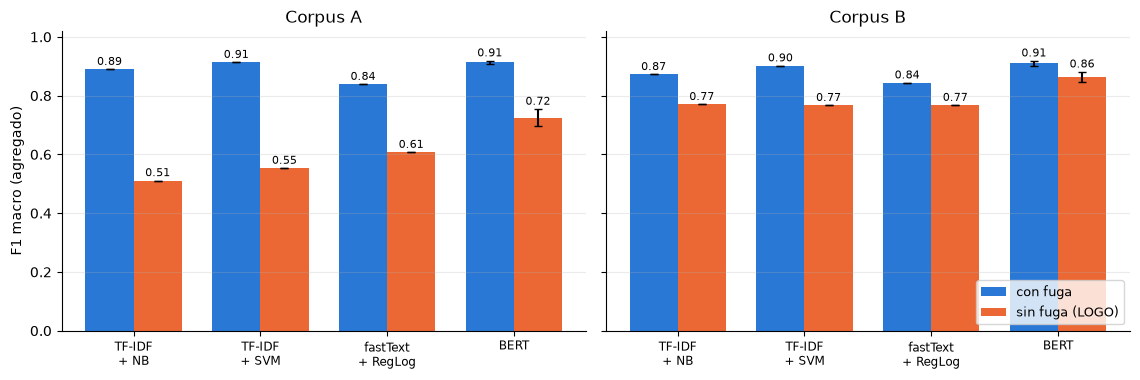

In [7]:
nombres_cortos = {"TF-IDF + MNB": "TF-IDF\n+ NB",
                  "TF-IDF + LinearSVC": "TF-IDF\n+ SVM",
                  "fastText + LogReg": "fastText\n+ RegLog",
                  "BERT (NoRBERT)": "BERT"}
fig, ejes = plt.subplots(1, 2, figsize=(11.5, 3.9), sharey=True)
for eje, letra in zip(ejes, ("A", "B")):
    sub = maestra[maestra.corpus == letra]
    modelos_aqui = [m for m in MODELOS if m in sub.modelo.values]
    x = np.arange(len(modelos_aqui))
    for despl, modo, color in ((-0.19, "con fuga", "#2a78d6"),
                               (0.19, "sin fuga (LOGO)", "#eb6834")):
        vals = [sub[(sub.modelo == m) & (sub.modo == modo)]["F1 macro"].iloc[0]
                for m in modelos_aqui]
        errs = [sub[(sub.modelo == m) & (sub.modo == modo)]["desv F1 macro"].iloc[0]
                for m in modelos_aqui]
        eje.bar(x + despl, vals, 0.38, yerr=errs, capsize=3, label=modo,
                color=color)
        for xi, (v, e) in enumerate(zip(vals, errs)):
            eje.annotate(f"{v:.2f}", (xi + despl, v + e + 0.015), ha="center",
                         fontsize=8)
    eje.set_xticks(x, [nombres_cortos[m] for m in modelos_aqui], fontsize=8.5)
    eje.set_title(f"Corpus {letra}")
    eje.set_ylim(0, 1.02)
    eje.spines[["top", "right"]].set_visible(False)
    eje.yaxis.grid(True, alpha=0.25)
ejes[0].set_ylabel("F1 macro (agregado)")
ejes[1].legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(DIR_FIGURAS, "nivel1_brecha.pdf"))
plt.show()

## 6. Matrices de confusión

Una matriz agregada por modelo y modo (filas: etiqueta real). En BERT se agregan las predicciones de las 5 semillas, así que los conteos son cinco veces el corpus; los porcentajes por fila son comparables.

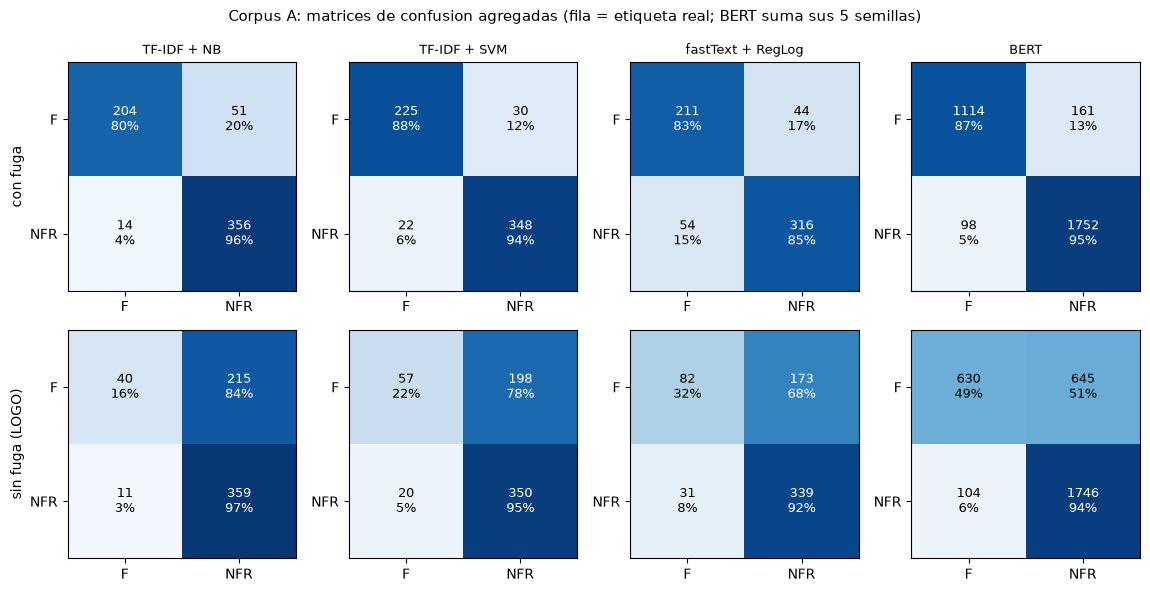

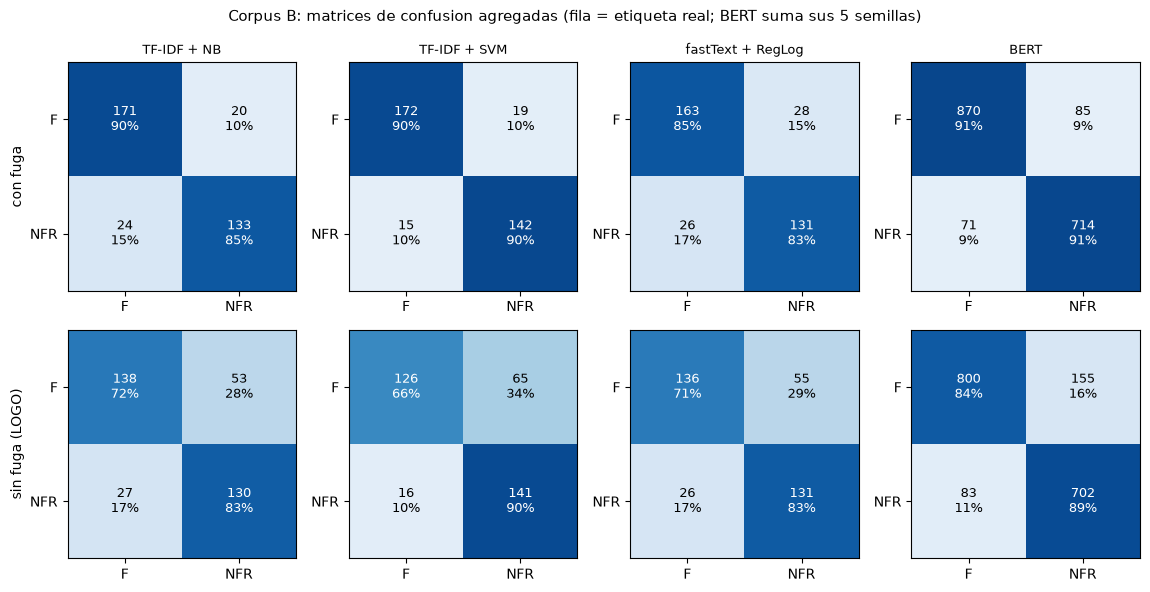

In [8]:
def pred_de(nombre, modo, letra):
    if nombre == "BERT (NoRBERT)":
        if (modo, letra) not in bert:
            return None
        d = bert[(modo, letra)]
    else:
        d = predicciones[(modo, letra)]
        d = d[d.modelo == nombre]
    return d

for letra in ("A", "B"):
    cols = [m for m in MODELOS if pred_de(m, "confuga", letra) is not None]
    fig, ejes = plt.subplots(2, len(cols), figsize=(2.9 * len(cols), 6.0))
    for i, modo in enumerate(("confuga", "logo")):
        for j, nombre in enumerate(cols):
            d = pred_de(nombre, modo, letra)
            M = confusion_matrix(d.etiqueta, d.prediccion, labels=CLASES)
            pct = M / M.sum(axis=1, keepdims=True)
            eje = ejes[i][j]
            eje.imshow(pct, cmap="Blues", vmin=0, vmax=1)
            for r in range(2):
                for c in range(2):
                    color = "white" if pct[r, c] > 0.6 else "black"
                    eje.text(c, r, f"{M[r, c]}\n{pct[r, c]:.0%}", ha="center",
                             va="center", color=color, fontsize=9)
            eje.set_xticks([0, 1], CLASES)
            eje.set_yticks([0, 1], CLASES)
            if i == 0:
                eje.set_title(nombres_cortos[nombre].replace("\n", " "),
                              fontsize=9)
            if j == 0:
                eje.set_ylabel("con fuga" if modo == "confuga"
                               else "sin fuga (LOGO)", fontsize=10)
    fig.suptitle(f"Corpus {letra}: matrices de confusion agregadas "
                 "(fila = etiqueta real; BERT suma sus 5 semillas)", fontsize=11)
    fig.tight_layout()
    fig.savefig(os.path.join(DIR_FIGURAS, f"nivel1_confusion_{letra}.pdf"))
    plt.show()

## 7. Desempeño por proyecto bajo LOGO

Exactitud por proyecto (accuracy y no F1, porque hay proyectos con una sola clase), con los proyectos ordenados por tamaño. En BERT, el promedio de sus 5 semillas.

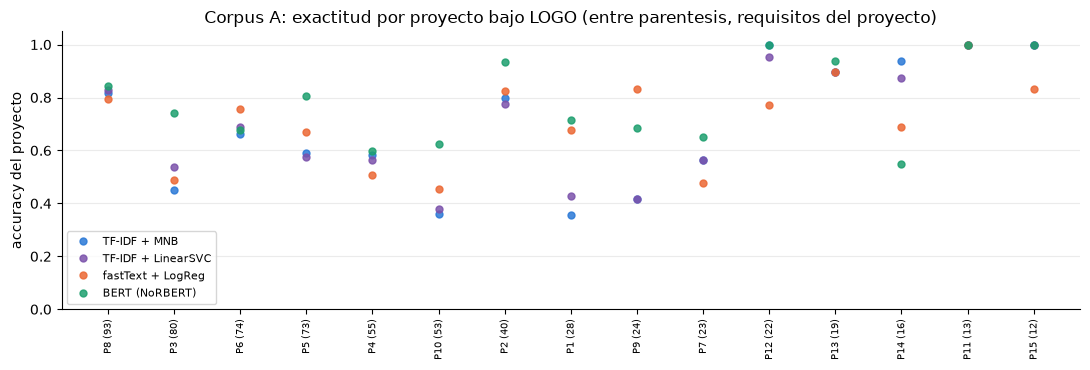

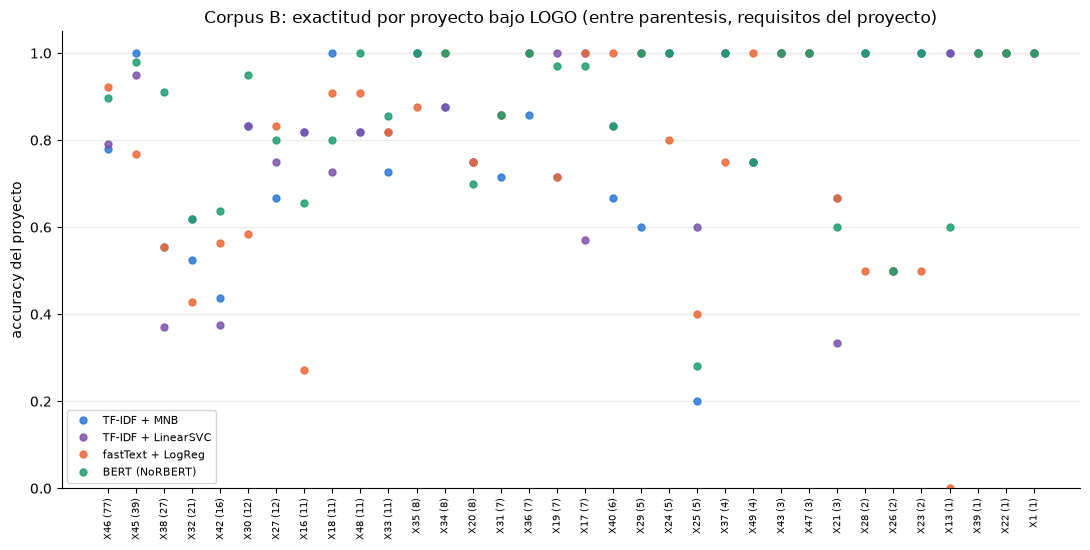

In [9]:
colores = {"TF-IDF + MNB": "#2a78d6", "TF-IDF + LinearSVC": "#7b52ab",
           "fastText + LogReg": "#eb6834", "BERT (NoRBERT)": "#1d9f6e"}
for letra in ("A", "B"):
    base = predicciones[("logo", letra)]
    tam = base[base.modelo == MODELOS_CLASICOS[0]].groupby("proyecto").size()
    orden_p = tam.sort_values(ascending=False).index.tolist()
    fig, eje = plt.subplots(figsize=(11, 3.8 if letra == "A" else 5.6))
    for nombre in MODELOS:
        d = pred_de(nombre, "logo", letra)
        if d is None:
            continue
        acc = d.assign(ok=(d.etiqueta == d.prediccion)).groupby("proyecto").ok.mean()
        eje.plot(range(len(orden_p)), acc.loc[orden_p].values, "o", ms=5,
                 label=nombre, color=colores[nombre], alpha=0.85)
    eje.set_xticks(range(len(orden_p)),
                   [f"{p} ({tam[p]})" for p in orden_p], rotation=90, fontsize=7)
    eje.set_ylabel("accuracy del proyecto")
    eje.set_ylim(0, 1.05)
    eje.set_title(f"Corpus {letra}: exactitud por proyecto bajo LOGO "
                  "(entre parentesis, requisitos del proyecto)")
    eje.yaxis.grid(True, alpha=0.25)
    eje.spines[["top", "right"]].set_visible(False)
    eje.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(os.path.join(DIR_FIGURAS, f"nivel1_por_proyecto_{letra}.pdf"))
    plt.show()

## 8. Salidas

En `datasets/nivel1/`: las predicciones por bloque (clásicos y BERT), `nivel1_metricas.csv` y las figuras en `figuras/`.